In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns
import random
from pathlib import Path
import datetime
import joblib
import shutil
from scipy.ndimage import gaussian_filter
from scipy.signal import find_peaks
from statistics import mean
# from sklearn.metrics.pairwise import cosine_similarity

sys.path.insert(0, "../../Python/cellular_cycle")
from model_fxns import get_traj, plot_traj, restructProt, cosine_similarity, get_cos_similarities


# locations of previously generated simulation data
SAVE_DIR = Path('~/ECM_mod_output').expanduser()
SAVE_DIR.mkdir(exist_ok=True)   # create the directory if it doesn't exist  

SAVEFILES = True
OVERWRITE = True


SAVE_DIR = Path("~/ECM_mod_output/").expanduser()
LYAP_DIR = Path(SAVE_DIR,'sweep_UMAP')
EMBED_DIR = Path('../../Data','UMAP_embedding_ode') # location of saved embedding files for each condition

SET_JPARAM = False # Set the parameters for the simulation

sys_type = sys.platform

output_from = 1 # 1: original, 2: PSO params, 3: 03_ECM_model_output.ipynb, 4: 04_Stoch_sims_for_UMAP.ipynb

if sys_type == 'darwin':
    sys_name = 'mac'
elif sys_type == 'win32': 
    sys_name = 'win'
elif sys_type == 'linux': 
    sys_name = 'linux'

In [2]:
rcParams.update({'figure.autolayout': True})

In [3]:
# ------------------------------------------------------------------
# Load updated Lyapunov summary CSV
# ------------------------------------------------------------------
NOTEBOOK_DIR = Path.cwd()  # or Path(__file__).parent if in a script

PROJECT_ROOT = NOTEBOOK_DIR.parent.parent
LYAP_SUMMARY_CSV = PROJECT_ROOT / "Python" / "LYAP_FIGURES" / "_summaries" / "lyap_means_with_markers.csv"
lyap_df = pd.read_csv(LYAP_SUMMARY_CSV)

# enforce expected treatment order
treatments = ["DMSO", "ERL", "LOW"]

# sort in sweep order
lyap_df = lyap_df.sort_values(["treatment", "index"]).reset_index(drop=True)


summary_by_treatment = {}
for treatment in treatments:
    sub = lyap_df.loc[lyap_df["treatment"] == treatment].sort_values("index").reset_index(drop=True)

    if len(sub) != 151:
        raise ValueError(f"{treatment} has {len(sub)} rows, expected 151")

    summary_by_treatment[treatment] = {
        "mean_lyap": sub["mean_lyap"].to_numpy(dtype=float),
        "dyn_state": sub["dyn_state"].to_numpy(dtype=object),
        "steady_lambda_real": sub["steady_lambda_real"].to_numpy(dtype=float),
        "AKT": sub["AKT"].to_numpy(dtype=float),
        "FAK": sub["FAK"].to_numpy(dtype=float),
        "ERK": sub["ERK"].to_numpy(dtype=float),
        "index": sub["index"].to_numpy(dtype=int),
    }

lyap_dmso = summary_by_treatment["DMSO"]["mean_lyap"]
lyap_erl  = summary_by_treatment["ERL"]["mean_lyap"]
lyap_low  = summary_by_treatment["LOW"]["mean_lyap"]

state_dmso = summary_by_treatment["DMSO"]["dyn_state"]
state_erl  = summary_by_treatment["ERL"]["dyn_state"]
state_low  = summary_by_treatment["LOW"]["dyn_state"]

steady_dmso = summary_by_treatment["DMSO"]["steady_lambda_real"]
steady_erl  = summary_by_treatment["ERL"]["steady_lambda_real"]
steady_low  = summary_by_treatment["LOW"]["steady_lambda_real"]

In [4]:
def _interp_nans(y):
    y = np.asarray(y, dtype=float)
    x = np.arange(y.size)
    good = np.isfinite(y)
    if good.sum() == 0:
        return y.copy()
    if good.sum() == 1:
        out = np.full_like(y, np.nan)
        out[:] = y[good][0]
        return out
    return np.interp(x, x[good], y[good])

def smooth_series(y, window=11):
    y_filled = _interp_nans(y)
    w = int(window)
    if w < 3:
        return y_filled
    if w % 2 == 0:
        w += 1
    pad = w // 2
    y_pad = np.pad(y_filled, (pad, pad), mode="edge")
    kernel = np.ones(w, dtype=float) / w
    return np.convolve(y_pad, kernel, mode="valid")

def make_line_without_steady(y_raw, states, y_steady, window=11):
    y_smooth = smooth_series(y_raw, window=window)
    steady_mask = (states == "steady_state") & np.isfinite(y_steady)
    y_line = y_smooth.copy()
    y_line[steady_mask] = np.nan
    return y_line, y_smooth, steady_mask

### Load UMAP embeddings

`all_embedding_ode_conds_mac_from_04.sav` should have:
```
ODE_sim_DMSO_stiff_000_orig.csv
ODE_sim_DMSO_stiff_029_orig.csv
ODE_sim_DMSO_stiff_049_orig.csv
ODE_sim_DMSO_stiff_074_orig.csv
ODE_sim_DMSO_stiff_099_orig.csv
ODE_sim_ERL_stiff_000_orig.csv
ODE_sim_ERL_stiff_029_orig.csv
ODE_sim_ERL_stiff_049_orig.csv
ODE_sim_ERL_stiff_074_orig.csv
ODE_sim_ERL_stiff_099_orig.csv
```

`all_embedding_ode_conds_mac_from_03.sav` should be in the following order:
```
0, stiff_DMSO
1, stiff_ERL
2, int_DMSO
3, int_ERL
4, soft_DMSO
5, soft_ERL
```



In [3]:
# if output_from == 1:
#     embed_source = 'orig'
# elif output_from == 2:
#     embed_source = 'psoparams'
# else:
#     embed_source = f'from_0{output_from}'
#
# if SET_JPARAM:
#     all_embed_odes = joblib.load(Path(SAVE_DIR, f'all_embedding_ode_conds_{embed_source}_{sys_name}.sav'))
# else:
#     all_embed_odes = joblib.load(Path(LYAP_DIR, f'all_embedding_ode_conds_{sys_name}_{embed_source}.sav'))
#
# low_embed_ode = joblib.load(Path(SAVE_DIR, 'embedding_low_input_ode_orig.sav'))
# low_cycle_embed_ode = joblib.load(Path(SAVE_DIR, 'embedding_on_60_ode_orig.sav'))
# all_embed_odes.shape

(20000, 2)

In [5]:
UMAP_filepaths = [str(Path(LYAP_DIR, f)) for f in os.listdir(LYAP_DIR) if '.csv' in f and 'embedding' in f]

In [6]:
filenames_erl = [f for f in UMAP_filepaths if 'ERL' in f]
filenames_erl.sort()
filenames_dmso = [f for f in UMAP_filepaths if 'DMSO' in f]
filenames_dmso.sort()
filenames_low = [f for f in UMAP_filepaths if 'LOW' in f]
filenames_low.sort()

In [7]:
low_embed = filenames_low

In [8]:
if output_from == 1:
    embed_source = 'orig'
elif output_from == 2:
    embed_source = 'psoparams'
else:
    embed_source = f'from_0{output_from}'

if SET_JPARAM:
    all_embed_stoch = joblib.load(Path(SAVE_DIR, f'all_embedding_stoch_conds_{embed_source}_{sys_name}.sav'))
else:
    all_embed_stoch = joblib.load(Path(SAVE_DIR, f'all_embedding_stoch_conds_{sys_name}_{embed_source}.sav')) # output of 05_UMAP_of_stoch_sims.ipynb (experimental conds)
all_embed_stoch.shape

(399930, 2)

### Define conditions and associated annotations
condition names, colors, line types, etc.

In [9]:
conds = ['0.0 DMSO', '0.3 DMSO', '0.5 DMSO', '0.75 DMSO', '1.0 DMSO','0.0 EGFRi', '0.3 EGFRi', '0.5 EGFRi', '0.75 EGFRi', '1.0 EGFRi',]
colors_blue = plt.cm.Blues(np.linspace(0,1,7))
colors_red = plt.cm.Reds(np.linspace(0,1,7))
cond_colors = [colors_blue[2], colors_blue[3], colors_blue[4], colors_blue[5], colors_blue[6], colors_red[2], colors_red[3], colors_red[4], colors_red[5], colors_red[6],]
conds_idx = [0,1,2,3,4,5,6,7,8,9,]
plot_ode_len = [120,100,0,100,60,150,0,80,0,60,]
line_type = ['-', '-', '-', '-', '-', '--', '--', '--', '--', '--',]

# conds_idx_exp = [0,2,4,5,7,9,]
# exp_conds = [conds[i] for i in conds_idx_exp]
# exp_conds_names = ['soft DMSO', 'int DMSO', 'stiff DMSO', 'soft ERL', 'int ERL', 'stiff ERL',]

# lyap_conds_idx = [0,1,3,4,5,7,9,]
# lyap_conds = [conds[i] for i in lyap_conds_idx]

# colors_accent = plt.cm.jet(np.linspace(0,1,10))

### Load simulation data

In [10]:
if SET_JPARAM:
    all_prot = joblib.load(Path(SAVE_DIR, f'all_prot_stoch_conds_{embed_source}_{sys_name}.sav'))
else:
    all_prot = joblib.load(Path(SAVE_DIR, f'all_prot_stoch_conds_{sys_name}_{embed_source}.sav'))
all_prot.shape

(399930, 720)

In [11]:
trk_len = 2000 # length of ODE trajectories
 
if output_from == 3:
    num_conds = 6 # experimental conditions
elif output_from == 1 or output_from == 2 or output_from == 4:
    num_conds = 10
trk_len_stoch = int(len(all_embed_stoch)/num_conds) # lyapunov-determined stiffness conditions

# embed_array = all_embed_odes
embed_array_stoch = all_embed_stoch

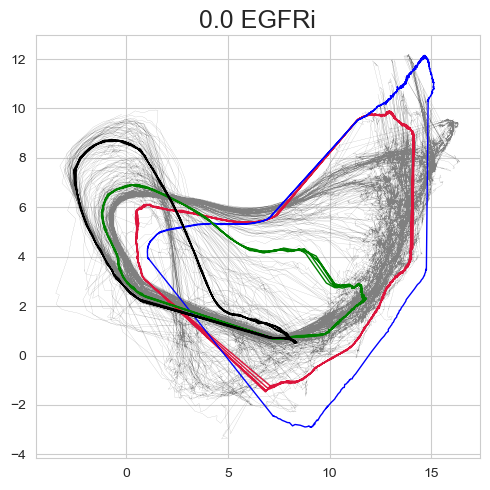

In [12]:
plot_traj(embed_array_stoch, 5, trk_len_stoch, title=conds[5])
tmp_emb = np.genfromtxt(filenames_erl[10], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
plt.plot(tmp_emb[:, 0], tmp_emb[:, 1], color="crimson", lw=1,)

tmp_emb = np.genfromtxt(filenames_low[0], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
plt.plot(tmp_emb[3000:, 0], tmp_emb[3000:, 1], color="blue",   lw=1)

tmp_emb = np.genfromtxt(filenames_erl[50], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
plt.plot(tmp_emb[:, 0], tmp_emb[:, 1], color="green",   lw=1)

tmp_emb = np.genfromtxt(filenames_erl[100], delimiter=",")
tmp_l   = int(len(tmp_emb) / 4)
plt.plot(tmp_emb[:, 0], tmp_emb[:, 1], color="black",   lw=1)


### Plot experimental conditions

In [13]:
# plot parameters
size = (3,3)
l = trk_len
lw=2
fontsize = 7

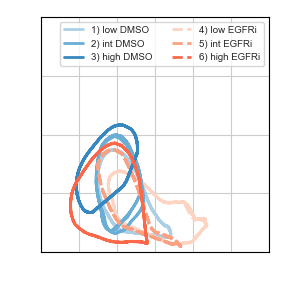

In [14]:
fig = plt.figure(figsize=size)

tmp_emb = np.genfromtxt(filenames_dmso[50], delimiter=",")
plt.plot(tmp_emb[:, 0], tmp_emb[:, 1], ls='-', lw=lw, alpha=1, color=colors_blue[2], label='1) low DMSO')
tmp_emb = np.genfromtxt(filenames_erl[50], delimiter=",")
plt.plot(tmp_emb[:, 0], tmp_emb[:, 1], ls='--', lw=lw, alpha=1, color=colors_red[1], label='4) low EGFRi')

tmp_emb = np.genfromtxt(filenames_dmso[100], delimiter=",")
plt.plot(tmp_emb[:, 0], tmp_emb[:, 1], ls='-', lw=lw, alpha=1, color=colors_blue[3], label='2) int DMSO')
tmp_emb = np.genfromtxt(filenames_erl[100], delimiter=",")
plt.plot(tmp_emb[:, 0], tmp_emb[:, 1], ls='--', lw=lw, alpha=1, color=colors_red[2], label='5) int EGFRi')

tmp_emb = np.genfromtxt(filenames_dmso[150], delimiter=",")
plt.plot(tmp_emb[:, 0], tmp_emb[:, 1], ls='-', lw=lw, alpha=1, color=colors_blue[4], label='3) high DMSO')
tmp_emb = np.genfromtxt(filenames_erl[150], delimiter=",")
plt.plot(tmp_emb[:, 0], tmp_emb[:, 1], ls='--', lw=lw, alpha=1, color=colors_red[3], label='6) high EGFRi')




plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [0,2,4,1,3,5]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order],
           loc="upper right", ncol=2, fontsize=fontsize)


### Plot figure


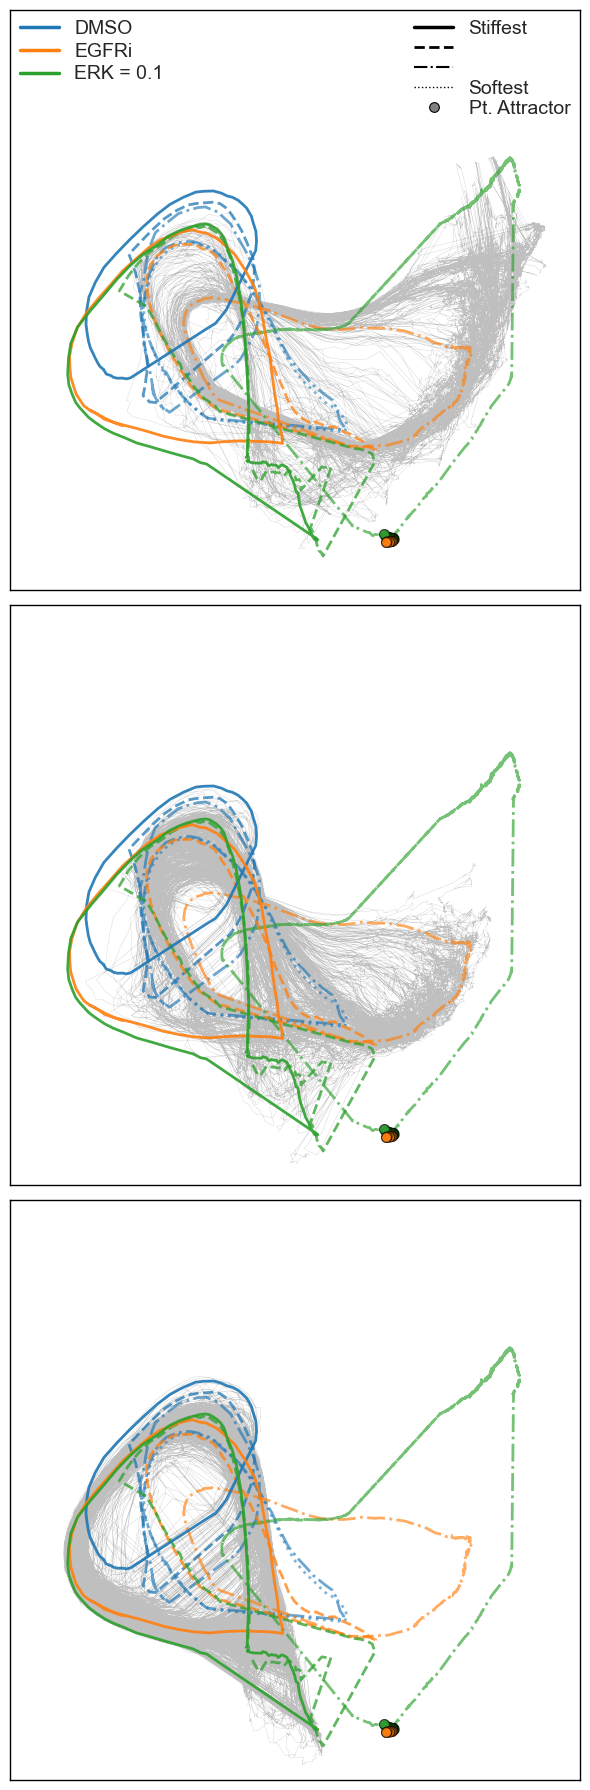

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

x = np.linspace(0.0, 3.0, 151)
xmin, xmax = -9, 18
ymin, ymax = -5, 18

def nearest_index_to_target(vals, x, target, window=0.15):
    mask = (x >= target - window) & (x <= target + window)
    idxs = np.where(mask)[0]
    if len(idxs) == 0:
        raise ValueError(f"No indices found near target {target}")
    return idxs[np.nanargmin(vals[idxs])]

selected = {
    "DMSO": [
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 1.0, window=0.2),
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 1.6, window=0.2),
        117,
        150,
    ],
    "ERL": [
        nearest_index_to_target(summary_by_treatment["ERL"]["mean_lyap"], x, 0.75, window=0.2),
        nearest_index_to_target(summary_by_treatment["ERL"]["mean_lyap"], x, 2.0, window=0.25),
        150,
    ],
    "LOW": [
        0,
        nearest_index_to_target(summary_by_treatment["LOW"]["mean_lyap"], x, 2.3, window=0.2),
        150,
    ],
}

# de-duplicate while preserving order
for treatment in selected:
    seen = set()
    selected[treatment] = [i for i in selected[treatment] if not (i in seen or seen.add(i))]

# ── Style maps ────────────────────────────────────────────────────────────────
linestyles = [":",  "-.", "--", "-"]
linewidths = [2.0,  2.0,  2.0, 2.0]
alphas     = [0.55, 0.65, 0.75, 0.90]
zorders    = [2,    3,    4,    5]

file_map   = {"DMSO": filenames_dmso, "ERL": filenames_erl, "LOW": low_embed}
color_map  = {"DMSO": "#1f77b4", "ERL": "#ff7f0e", "LOW": "#2ca02c"}
label_dict = {"ERL": "EGFRi", "LOW": "ERK = 0.1"}

lengths_map = {
    "DMSO": [55, 100, 45, 45],
    "ERL":  [195, 62, 60],
    "LOW":  [100, 100, 100],
}

attractor_map = {
    "LOW":  (lyap_df, low_embed),
    "ERL":  (lyap_df, filenames_erl),
    "DMSO": (lyap_df, filenames_dmso),
}

# ── Figure: 3 panels stacked vertically ──────────────────────────────────────
stoch_conds = [5, 7, 9]

fig, axes = plt.subplots(3, 1, figsize=(6, 18), sharex=True)
fig.patch.set_facecolor("white")

for panel_i, cond_x in enumerate(stoch_conds):
    ax = axes[panel_i]
    ax.set_facecolor("white")

    # ── Gray stochastic background ───────────────────────────────────────────
    ax.plot(
        embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch, 0],
        embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch, 1],
        lw=0.2, alpha=0.5, color="gray",
        zorder=1,
        label="_nolegend_",
    )

    # ── ODE trajectories ────────────────────────────────────────────────────
    for treatment in ["DMSO", "ERL", "LOW"]:
        file_list = file_map[treatment]
        color     = color_map[treatment]
        n_sel     = len(selected[treatment])

        for rank, i in enumerate(selected[treatment]):
            ls  = linestyles[-n_sel:][rank]
            lw  = linewidths[-n_sel:][rank]
            alp = alphas[-n_sel:][rank]
            zo  = zorders[-n_sel:][rank]

            tmp_emb = np.genfromtxt(file_list[i], delimiter=",")
            tmp_l   = lengths_map[treatment][rank]

            if (treatment == "LOW") and (rank == 0):
                ax.plot(
                    tmp_emb[3000:, 0], tmp_emb[3000:, 1],
                    color=color, linestyle=ls, linewidth=lw,
                    alpha=alp, zorder=zo, label="_nolegend_",
                )
            else:
                ax.plot(
                    tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1],
                    color=color, linestyle=ls, linewidth=lw,
                    alpha=alp, zorder=zo, label="_nolegend_",
                )

    # ── Point attractors ────────────────────────────────────────────────────
    for treatment, (df, file_list) in attractor_map.items():
        ss_idx = df[
            (df.treatment == treatment) & (df.dyn_state == "steady_state")
        ]["index"].values

        if len(ss_idx) == 0:
            continue

        coords = np.array([
            np.genfromtxt(file_list[i], delimiter=",")[-1] for i in ss_idx
        ])

        ax.scatter(
            coords[:, 0], coords[:, 1],
            s=50, facecolor=color_map[treatment],
            edgecolor="black", linewidths=0.8,
            zorder=6, alpha=0.5,
        )

    # ── Strip ticks/labels/titles ───────────────────────────────────────────
    ax.set_xlim([xmin, xmax])
    ax.set_ylim([ymin, ymax])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")
    ax.grid(False)

    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(1.0)

# ── Split legend on the top panel ────────────────────────────────────────────
# Legend 1: treatment colors (upper left)
treatment_handles = [
    Line2D([0], [0], color=color_map["DMSO"], lw=2.5, ls="-", label="DMSO"),
    Line2D([0], [0], color=color_map["ERL"],  lw=2.5, ls="-", label="EGFRi"),
    Line2D([0], [0], color=color_map["LOW"],  lw=2.5, ls="-", label="ERK = 0.1"),
]

leg1 = axes[0].legend(
    handles=treatment_handles,
    fontsize=14, loc="upper left",
    labelspacing=0.25, borderpad=0,
    frameon=False, facecolor="white", edgecolor="lightgrey", framealpha=1,
)

# Legend 2: stiffness key + point attractor (upper right)
stiff_handles = [
    Line2D([0], [0], color="black", lw=2.5, ls="-",  label="Stiffest"),
    Line2D([0], [0], color="black", lw=2.0, ls="--", label=""),
    Line2D([0], [0], color="black", lw=1.5, ls="-.", label=""),
    Line2D([0], [0], color="black", lw=1.0, ls=":",  label="Softest"),
    Line2D([0], [0], color="black", lw=0,   ls="",
           marker="o", markersize=7,
           markerfacecolor="grey", markeredgecolor="black",
           markeredgewidth=0.8, label="Pt. Attractor"),
]

axes[0].legend(
    handles=stiff_handles,
    fontsize=14, loc="upper right",
    labelspacing=0.1, borderpad=0,
    frameon=False, facecolor="white", framealpha=1,
)

# Re-add leg1 since the second legend call replaces it by default
axes[0].add_artist(leg1)

plt.tight_layout()
plt.show()

In [16]:
all_time_tmp = joblib.load(Path(SAVE_DIR, f'all_time_tmp_{sys_name}_{embed_source}.sav'))


In [17]:
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']

# order = [0,1,3,4,5,7,9,]

dmso_000_prot_df = pd.DataFrame(all_prot[0*trk_len_stoch:1*trk_len_stoch,:])
dmso_000_time_df = pd.DataFrame(all_time_tmp[0*trk_len_stoch:1*trk_len_stoch,:])
dmso_000_emb_df = pd.DataFrame(all_embed_stoch[0*trk_len_stoch:1*trk_len_stoch,:])

dmso_030_prot_df = pd.DataFrame(all_prot[1*trk_len_stoch:2*trk_len_stoch,:])
dmso_030_time_df = pd.DataFrame(all_time_tmp[1*trk_len_stoch:2*trk_len_stoch,:])
dmso_030_emb_df = pd.DataFrame(all_embed_stoch[1*trk_len_stoch:2*trk_len_stoch,:])

dmso_050_prot_df = pd.DataFrame(all_prot[2*trk_len_stoch:3*trk_len_stoch,:])
dmso_050_time_df = pd.DataFrame(all_time_tmp[2*trk_len_stoch:3*trk_len_stoch,:])
dmso_050_emb_df = pd.DataFrame(all_embed_stoch[2*trk_len_stoch:3*trk_len_stoch,:])

dmso_070_prot_df = pd.DataFrame(all_prot[3*trk_len_stoch:4*trk_len_stoch,:])
dmso_070_time_df = pd.DataFrame(all_time_tmp[3*trk_len_stoch:4*trk_len_stoch,:])
dmso_070_emb_df = pd.DataFrame(all_embed_stoch[3*trk_len_stoch:4*trk_len_stoch,:])

dmso_099_prot_df = pd.DataFrame(all_prot[4*trk_len_stoch:5*trk_len_stoch,:])
dmso_099_time_df = pd.DataFrame(all_time_tmp[4*trk_len_stoch:5*trk_len_stoch,:])
dmso_099_emb_df = pd.DataFrame(all_embed_stoch[4*trk_len_stoch:5*trk_len_stoch,:])

erl_000_prot_df = pd.DataFrame(all_prot[5*trk_len_stoch:6*trk_len_stoch,:])
erl_000_time_df = pd.DataFrame(all_time_tmp[5*trk_len_stoch:6*trk_len_stoch,:])
erl_000_emb_df = pd.DataFrame(all_embed_stoch[5*trk_len_stoch:6*trk_len_stoch,:])

erl_050_prot_df = pd.DataFrame(all_prot[7*trk_len_stoch:8*trk_len_stoch,:])
erl_050_time_df = pd.DataFrame(all_time_tmp[7*trk_len_stoch:8*trk_len_stoch,:])
erl_050_emb_df = pd.DataFrame(all_embed_stoch[7*trk_len_stoch:8*trk_len_stoch,:])

erl_099_prot_df = pd.DataFrame(all_prot[9*trk_len_stoch:10*trk_len_stoch,:])
erl_099_time_df = pd.DataFrame(all_time_tmp[9*trk_len_stoch:10*trk_len_stoch,:])
erl_099_emb_df = pd.DataFrame(all_embed_stoch[9*trk_len_stoch:10*trk_len_stoch,:])


### Import IMTs

In [18]:
IMT_lens = np.genfromtxt(Path(SAVE_DIR, 'IMTcount_param_orig.csv'), delimiter=',')


In [19]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)

In [20]:
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

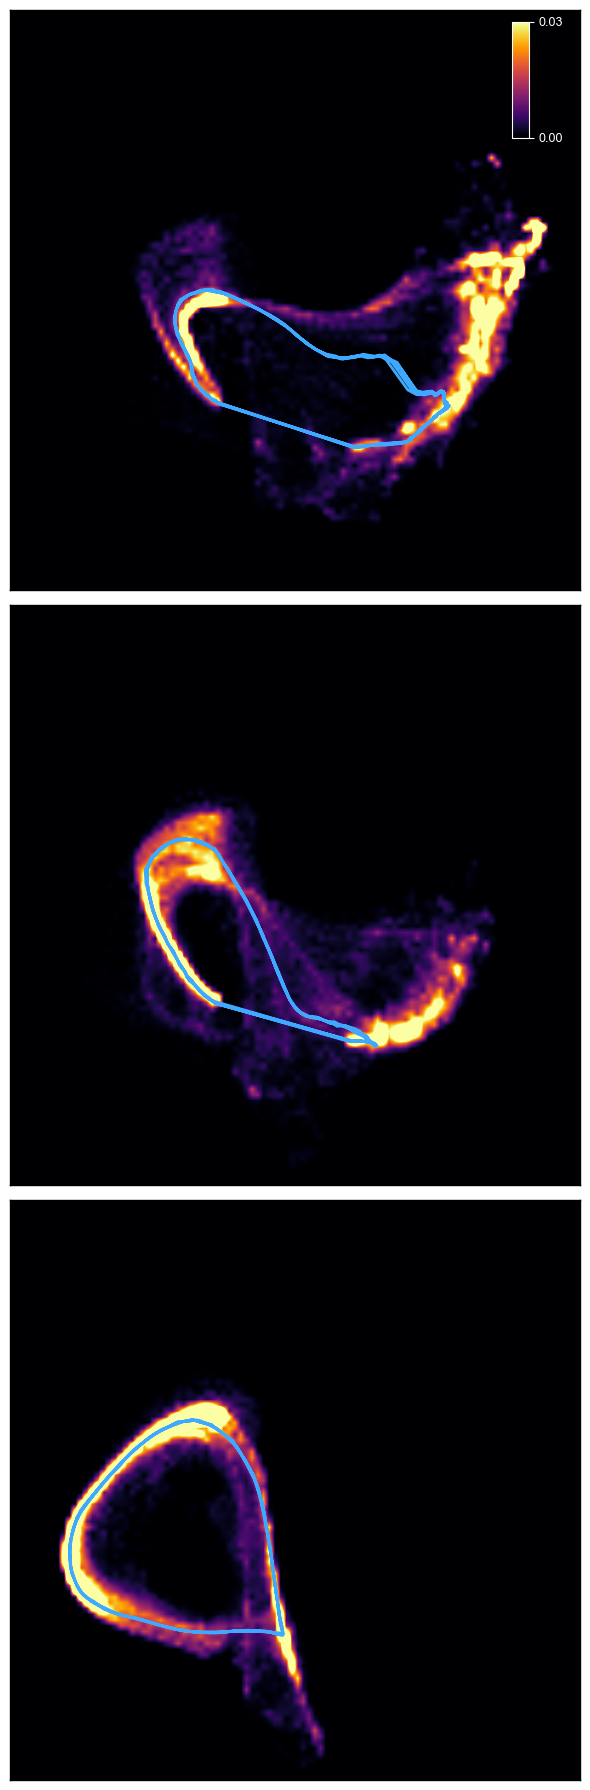

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from pathlib import Path

params = {
    'axes.titley': 1, 'axes.titlepad': 5,
    'axes.labelsize': 16, 'axes.edgecolor': "black", 'axes.titlesize': 18,
    'xtick.labelsize': 14, 'ytick.labelsize': 14,
}
plt.rcParams.update(params)

# ── Per-panel config ─────────────────────────────────────────────────────────
# (cond_x for stochastic heatmap, val suffix, ODE index, label)
panel_specs = [
    (5, '000', 50,  '4) low EGFRi'),   # top
    (7, '050', 100, '5) int EGFRi'),   # middle
    (9, '099', 150, '6) high EGFRi'),  # bottom
]

xmin, xmax = -9, 18
ymin, ymax = -5, 18
lw = 2
ode_color = "#3FA9FF"  # bright blue, pops against inferno

# ── Figure: 3 stacked panels ─────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(6, 18), sharex=True)
fig.patch.set_facecolor("white")

for panel_i, (cond_x, val, ode_idx, ode_label) in enumerate(panel_specs):
    ax = axes[panel_i]

    # ── Build the 2D histogram for this stochastic condition ────────────────
    dat_name = f'umap_win_erl_{val}'
    dat = globals()[dat_name]
    x = np.array(dat[0])
    y = np.array(dat[1])

    H, xedges, yedges = np.histogram2d(
        x, y, bins=100,
        range=[[xmin, xmax], [ymin, ymax]],
        density=True,
    )

    if 'erl' in dat_name:
        relative_H = np.divide(H, IMT_lens[panel_i + 2])
    else:
        relative_H = np.divide(H, IMT_lens[panel_i])
    sigma = [3, 3]
    H2 = gaussian_filter(relative_H, sigma, mode='constant')

    # ── Heatmap ─────────────────────────────────────────────────────────────
    im = ax.imshow(
        np.rot90(H),
        extent=[xmin, xmax, ymin, ymax],
        interpolation='bilinear', cmap='inferno', aspect='auto',
        zorder=1,
    )
    im.set_clim(0, 0.03)

    # ── ODE overlay (solid blue) ────────────────────────────────────────────
    tmp_emb = np.genfromtxt(filenames_erl[ode_idx], delimiter=",")
    ax.plot(
        tmp_emb[:, 0], tmp_emb[:, 1],
        ls='-', lw=lw, alpha=1,
        color=ode_color, label=ode_label,
        zorder=3,
    )

    # ── Colorbar: only on the top panel ─────────────────────────────────────
    if panel_i == 0:
        cbar_ax = ax.inset_axes([0.88, 0.78, 0.03, 0.2])
        cb = fig.colorbar(im, cax=cbar_ax, ticks=[0, 0.03])
        cb.ax.tick_params(labelsize=9, color='white', labelcolor='white')
        cb.outline.set_edgecolor('white')

    # ── Axis formatting: blank ticks/labels, keep frame ─────────────────────
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")
    ax.grid(False)

    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(1.0)

plt.tight_layout()
plt.show()

### Define a function to calculate cosine similarity

### Calculate cosine similarity for adjacent vectors along a trajectory
For each trajectory, define the set of vectors each of size `v_len` and index offset of `offset` for their comparator vectors to calculate cosine similarity.


In [22]:
offset=1
v_len=1

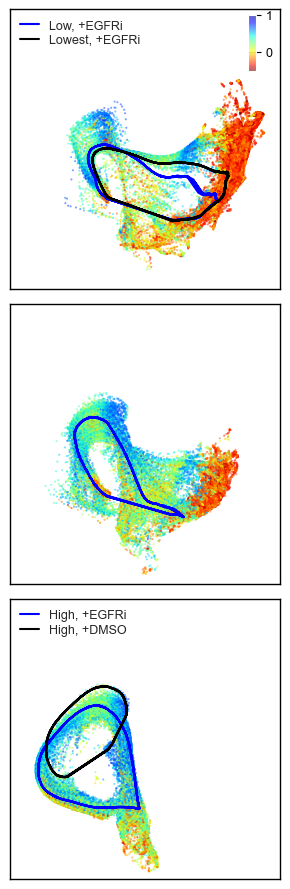

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

x = np.linspace(0.0, 3.0, 151)

# Per-panel: (cond_x for stochastic, ode_idx for filenames_erl, blue label)
panel_specs = [
    (5, 50,  "Low, +EGFRi"),    # top    — low stiffness
    (7, 100, None),             # middle — int stiffness (no legend)
    (9, 150, "High, +EGFRi"),   # bottom — high stiffness
]

ode_color = "blue"

fig, axes = plt.subplots(3, 1, figsize=(3, 9), sharex=True)
fig.patch.set_facecolor("white")

for panel_i, (cond_x, ode_idx, blue_label) in enumerate(panel_specs):
    ax = axes[panel_i]

    # ── Cosine-similarity scatter on stochastic trajectory ──────────────────
    cos_vals = get_cos_similarities(
        get_traj(all_prot, cond_x, trk_len_stoch), v_len, offset
    )
    dat = get_traj(embed_array_stoch, cond_x, trk_len_stoch - 2)
    scatter1 = ax.scatter(
        dat[:, 0], dat[:, 1],
        s=0.2, alpha=0.6,
        vmin=-0.5, vmax=1,
        c=cos_vals, cmap="jet_r",
        zorder=1,
    )

    # ── Blue ODE: matching stiffness for this row ───────────────────────────
    tmp_emb = np.genfromtxt(filenames_erl[ode_idx], delimiter=",")
    ax.plot(
        tmp_emb[:, 0], tmp_emb[:, 1],
        lw=1.5, alpha=1, color=ode_color, zorder=4,
        label=blue_label if blue_label else "_nolegend_",
    )

    # ── Top-panel extra: EGFRi at the lyap-target index ─────────────────────
    if panel_i == 0:
        erl_extra_idx = nearest_index_to_target(
            summary_by_treatment["ERL"]["mean_lyap"], x, 0.75, window=0.2
        )
        tmp_extra = np.genfromtxt(filenames_erl[erl_extra_idx], delimiter=",")
        ax.plot(
            tmp_extra[:, 0], tmp_extra[:, 1],
            lw=1.5, alpha=1, color="black", zorder=4,
            label="Lowest, +EGFRi",
        )

    # ── Bottom-panel extra: DMSO[150] ───────────────────────────────────────
    if panel_i == 2:
        tmp_extra = np.genfromtxt(filenames_dmso[150], delimiter=",")
        ax.plot(
            tmp_extra[:, 0], tmp_extra[:, 1],
            lw=1.5, alpha=1, color="black", zorder=4,
            label="High, +DMSO",
        )

    # ── Colorbar: top panel only ────────────────────────────────────────────
    if panel_i == 0:
        cbar_ax = ax.inset_axes([0.88, 0.78, 0.03, 0.2])
        cb = fig.colorbar(scatter1, cax=cbar_ax)
        cb.ax.tick_params(labelsize=9, color="black", labelcolor="black")
        cb.outline.set_edgecolor("white")

    # ── Legend: top and bottom panels only ──────────────────────────────────
    if panel_i in (0, 2):
        ax.legend(
            loc="upper left",
            fontsize=9,
            labelspacing=0.25,
            borderpad=0.3,
            handlelength=1.5,
            frameon=False,
        )

    # ── Axis formatting: blank ticks/labels, keep frame ─────────────────────
    xmin, xmax = -9, 18
    ymin, ymax = -5, 18
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")
    ax.grid(False)

    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(1.0)

plt.tight_layout()
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


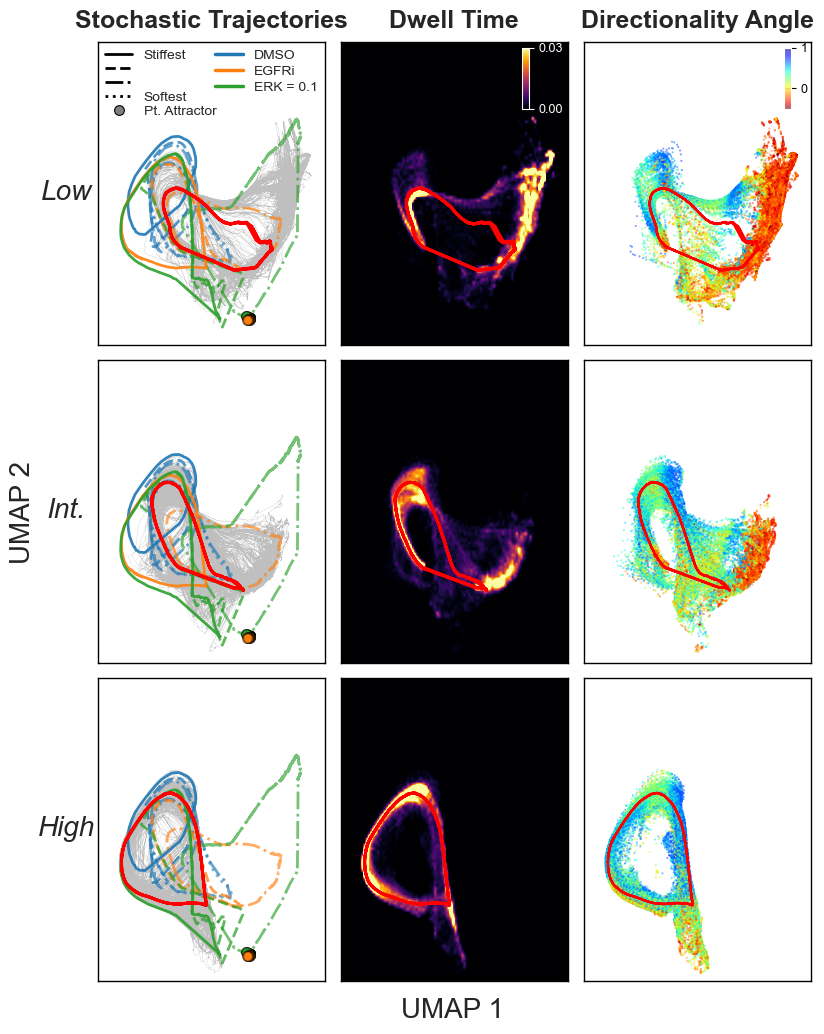

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

x = np.linspace(0.0, 3.0, 151)

# ── Per-row config ───────────────────────────────────────────────────────────
# (row label, cond_x for stoch panels, ode_idx for filenames_erl, blue label for col 2)
rows = [
    ("Low",  5, 50,  "Low, +EGFRi"),
    ("Int.", 7, 100, None),
    ("High", 9, 150, "High, +EGFRi"),
]

# ── Stochastic-Trajectories column setup (same as before) ────────────────────
selected = {
    "DMSO": [
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 1.0, window=0.2),
        nearest_index_to_target(summary_by_treatment["DMSO"]["mean_lyap"], x, 1.6, window=0.2),
        117,
        150,
    ],
    "ERL": [
        nearest_index_to_target(summary_by_treatment["ERL"]["mean_lyap"], x, 0.75, window=0.2),
        nearest_index_to_target(summary_by_treatment["ERL"]["mean_lyap"], x, 2.0, window=0.25),
        150,
    ],
    "LOW": [
        0,
        nearest_index_to_target(summary_by_treatment["LOW"]["mean_lyap"], x, 2.3, window=0.2),
        150,
    ],
}
for treatment in selected:
    seen = set()
    selected[treatment] = [i for i in selected[treatment] if not (i in seen or seen.add(i))]

linestyles = [":",  "-.", "--", "-"]
linewidths = [2.0,  2.0,  2.0, 2.0]
alphas     = [0.55, 0.65, 0.75, 0.90]
zorders    = [2,    3,    4,    5]

file_map   = {"DMSO": filenames_dmso, "ERL": filenames_erl, "LOW": low_embed}
color_map  = {"DMSO": "#1f77b4", "ERL": "#ff7f0e", "LOW": "#2ca02c"}

lengths_map = {
    "DMSO": [55, 100, 45, 45],
    "ERL":  [195, 62, 60],
    "LOW":  [100, 100, 100],
}
attractor_map = {
    "LOW":  (lyap_df, low_embed),
    "ERL":  (lyap_df, filenames_erl),
    "DMSO": (lyap_df, filenames_dmso),
}

# Suffix lookup for dwell-time heatmap data (umap_win_erl_<val>)
heatmap_suffix = {5: "000", 7: "050", 9: "099"}

# ── Limits (per column) ──────────────────────────────────────────────────────

xmin_traj, xmax_traj = -9, 18
ymin_traj, ymax_traj = -5, 18
xmin_hm,   xmax_hm   = -9, 18
ymin_hm,   ymax_hm   = -5, 18

ode_color = "blue"

# ── Build the 3×3 figure ─────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 3, figsize=(8.5, 11))
fig.patch.set_facecolor("white")

for row_i, (row_label, cond_x, ode_idx, blue_label_dir) in enumerate(rows):

    # ═══════════════ COLUMN 0: Stochastic Trajectories ════════════════════════
    ax = axes[row_i, 0]
    ax.set_facecolor("white")

    ax.plot(
        embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch, 0],
        embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch, 1],
        lw=0.2, alpha=0.5, color="gray", zorder=1, label="_nolegend_",
    )

    for treatment in ["DMSO", "ERL", "LOW"]:
        file_list = file_map[treatment]
        color     = color_map[treatment]
        n_sel     = len(selected[treatment])

        for rank, i in enumerate(selected[treatment]):
            ls  = linestyles[-n_sel:][rank]
            lw  = linewidths[-n_sel:][rank]
            alp = alphas[-n_sel:][rank]
            zo  = zorders[-n_sel:][rank]

            tmp_emb = np.genfromtxt(file_list[i], delimiter=",")
            tmp_l   = lengths_map[treatment][rank]

            if (treatment == "LOW") and (rank == 0):
                ax.plot(tmp_emb[3000:, 0], tmp_emb[3000:, 1],
                        color=color, linestyle=ls, linewidth=lw,
                        alpha=alp, zorder=zo, label="_nolegend_")
            else:
                ax.plot(tmp_emb[:tmp_l, 0], tmp_emb[:tmp_l, 1],
                        color=color, linestyle=ls, linewidth=lw,
                        alpha=alp, zorder=zo, label="_nolegend_")

    for treatment, (df, file_list) in attractor_map.items():
        ss_idx = df[(df.treatment == treatment) &
                    (df.dyn_state == "steady_state")]["index"].values
        if len(ss_idx) == 0:
            continue
        coords = np.array([np.genfromtxt(file_list[i], delimiter=",")[-1]
                           for i in ss_idx])
        ax.scatter(coords[:, 0], coords[:, 1],
                   s=50, facecolor=color_map[treatment],
                   edgecolor="black", linewidths=0.8,
                   zorder=6, alpha=0.5)

    tmp_emb = np.genfromtxt(filenames_erl[ode_idx], delimiter=",")
    ax.plot(tmp_emb[:, 0], tmp_emb[:, 1],
            ls="-", lw=2, alpha=1, color="red", zorder=10)

    ax.set_xlim(xmin_traj, xmax_traj)
    ax.set_ylim(ymin_traj, ymax_traj)

    # ═══════════════ COLUMN 1: Dwell Time ═════════════════════════════════════
    ax = axes[row_i, 1]
    val = heatmap_suffix[cond_x]
    dat = globals()[f"umap_win_erl_{val}"]
    x_h, y_h = np.array(dat[0]), np.array(dat[1])

    H, _, _ = np.histogram2d(
        x_h, y_h, bins=100,
        range=[[xmin_hm, xmax_hm], [ymin_hm, ymax_hm]], density=True,
    )

    im = ax.imshow(
        np.rot90(H), extent=[xmin_hm, xmax_hm, ymin_hm, ymax_hm],
        interpolation="bilinear", cmap="inferno", aspect="auto", zorder=1,
    )
    im.set_clim(0, 0.03)

    tmp_emb = np.genfromtxt(filenames_erl[ode_idx], delimiter=",")
    ax.plot(tmp_emb[:, 0], tmp_emb[:, 1],
            ls="-", lw=2, alpha=1, color="red", zorder=3)

    if row_i == 0:
        cbar_ax = ax.inset_axes([0.8, 0.78, 0.03, 0.2])
        cb = fig.colorbar(im, cax=cbar_ax, ticks=[0, 0.03])
        cb.ax.tick_params(labelsize=9, color="white", labelcolor="white")
        cb.outline.set_edgecolor("white")

    ax.set_xlim(xmin_traj, xmax_traj)
    ax.set_ylim(ymin_traj, ymax_traj)

    # ═══════════════ COLUMN 2: Directionality Angle ═══════════════════════════
    ax = axes[row_i, 2]

    cos_vals = get_cos_similarities(
        get_traj(all_prot, cond_x, trk_len_stoch), v_len, offset,
    )
    dat = get_traj(embed_array_stoch, cond_x, trk_len_stoch - 2)
    scatter1 = ax.scatter(
        dat[:, 0], dat[:, 1],
        s=0.2, alpha=0.6, vmin=-0.5, vmax=1,
        c=cos_vals, cmap="jet_r", zorder=1,
    )

    tmp_emb = np.genfromtxt(filenames_erl[ode_idx], delimiter=",")
    ax.plot(tmp_emb[:, 0], tmp_emb[:, 1],
            lw=1.5, alpha=1, color="red", zorder=4)

    # if row_i == 0:
    #     erl_extra_idx = nearest_index_to_target(
    #         summary_by_treatment["ERL"]["mean_lyap"], x, 0.75, window=0.2,
    #     )
    #     tmp_extra = np.genfromtxt(filenames_erl[erl_extra_idx], delimiter=",")
    #     ax.plot(tmp_extra[:, 0], tmp_extra[:, 1],
    #             lw=1.5, alpha=1, color="black", zorder=4,
    #             label="Lowest, +EGFRi")
    #
    # if row_i == 2:
    #     tmp_extra = np.genfromtxt(filenames_dmso[150], delimiter=",")
    #     ax.plot(tmp_extra[:, 0], tmp_extra[:, 1],
    #             lw=1.5, alpha=1, color="black", zorder=4,
    #             label="High, +DMSO")

    if row_i == 0:
        cbar_ax = ax.inset_axes([0.88, 0.78, 0.03, 0.2])
        cb = fig.colorbar(scatter1, cax=cbar_ax)
        cb.ax.tick_params(labelsize=9, color="black", labelcolor="black")
        cb.outline.set_edgecolor("white")

    if row_i in (0, 2):
        ax.legend(loc="upper left", fontsize=9,
                  labelspacing=0.25, borderpad=0.3,
                  handlelength=1.5, frameon=False)

    ax.set_xlim(xmin_traj, xmax_traj)
    ax.set_ylim(ymin_traj, ymax_traj)

# ── Common axis formatting: blank ticks, keep frame ─────────────────────────
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")
    ax.grid(False)
    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(1.0)

# ── Column titles (bold, on top row) ────────────────────────────────────────
col_titles = ["Stochastic Trajectories", "Dwell Time", "Directionality Angle"]
for col_i, title in enumerate(col_titles):
    axes[0, col_i].set_title(title, fontsize=18, pad=10, fontweight="bold")

# ── Row labels (italic, to the left of column 0) ────────────────────────────
row_labels = ["Low", "Int.", "High"]
for row_i, label in enumerate(row_labels):
    axes[row_i, 0].annotate(
        label,
        xy=(-0.14, 0.5), xycoords="axes fraction",
        fontsize=20, fontstyle="italic",
        ha="center", va="center",
    )

# ── Shared axis labels ───────────────────────────────────────────────────────
fig.text(0.56, 0.04, "UMAP 1", ha="center", fontsize=20)
fig.text(0.04, 0.5, "UMAP 2", va="center", rotation=90, fontsize=20)

# ── Split legend on the (0,0) panel ──────────────────────────────────────────
treatment_handles = [
    Line2D([0], [0], color=color_map["DMSO"], lw=2.5, ls="-", label="DMSO"),
    Line2D([0], [0], color=color_map["ERL"],  lw=2.5, ls="-", label="EGFRi"),
    Line2D([0], [0], color=color_map["LOW"],  lw=2.5, ls="-", label="ERK = 0.1"),
]
stiff_handles = [
    Line2D([0], [0], color="black", lw=2.0, ls="-",  label="Stiffest"),
    Line2D([0], [0], color="black", lw=2.0, ls="--", label=""),
    Line2D([0], [0], color="black", lw=2.0, ls="-.", label=""),
    Line2D([0], [0], color="black", lw=2.0, ls=":",  label="Softest"),
    Line2D([0], [0], color="black", lw=0,   ls="",
           marker="o", markersize=7,
           markerfacecolor="grey", markeredgecolor="black",
           markeredgewidth=0.8, label="Pt. Attractor"),
]
leg1 = axes[0, 0].legend(
    handles=treatment_handles, fontsize=10, loc="upper right",
    labelspacing=0.25, borderpad=0, frameon=False,
)
axes[0, 0].legend(
    handles=stiff_handles, fontsize=10, loc="upper left",
    labelspacing=0.1, borderpad=0, frameon=False,
)
axes[0, 0].add_artist(leg1)

plt.tight_layout(rect=[0.06, 0.06, 1, 0.97])

fig5 = Path(SAVE_DIR, 'fig5.png')
if SAVEFILES and (OVERWRITE or not fig5.exists()):
    plt.savefig(fig5, dpi=600)
else:
    plt.show()

NameError: name 'embed_array' is not defined

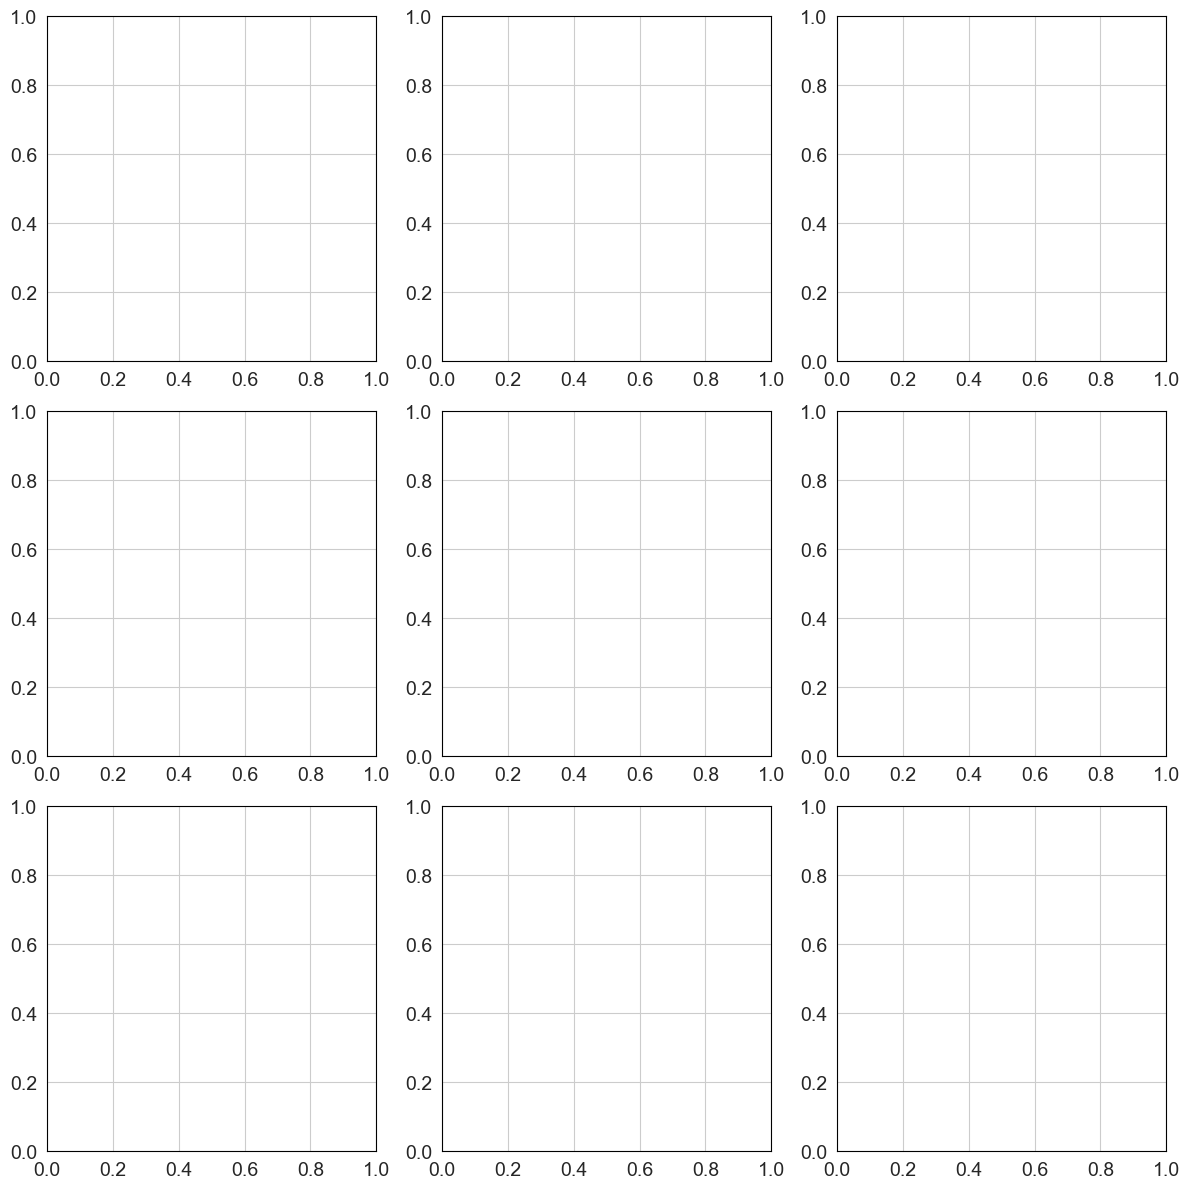

In [33]:
# Define figure size and grid
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
xmin = -10
xmax = 20
ymin = 0
ymax = 20

# Define row labels
row_labels = ['Soft', 'Int.', 'Stiff']

# Define column labels
col_labels = ['Stochastic Trajectories', 'Dwell Time', 'Directionality Angle']

# Column 1: Stochastic Trajectories
for cond_i, cond_x in enumerate([5, 7, 9]):
    lw = 2
    ax = axes[cond_i, 0]  # Select subplot
    
    for i, x in enumerate([0,1,3,4,5,7,9]):
        ax.plot(embed_array[x*l:x*l+plot_ode_len[x], 0],
                embed_array[x*l:x*l+plot_ode_len[x], 1],
                ls=line_type[x], lw=2, alpha=1, color=cond_colors[x], label=f'{i+1}) {conds[x]}')
    
    ax.plot(embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch, 0],
            embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch, 1],
            lw=0.2, alpha=0.5, color='gray', label=f'8) SSA')
    
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks([])
    ax.set_yticks([])
    if cond_i == 0:
        ax.legend(loc="upper left", ncol=2, fontsize=10)

# Column 2: Dwell Time
for cond_i, cond_x in enumerate([5, 7, 9]):
    val = ['000', '050', '099'][cond_i]
    dat_name = f'umap_win_erl_{val}'
    dat = globals()[dat_name]
    ax = axes[cond_i, 1]
    
    x = np.array(dat[0])
    y = np.array(dat[1])
    H, xedges, yedges = np.histogram2d(x, y, bins=100, range=[[xmin, xmax], [ymin, ymax]], density=True)
    relative_H = np.divide(H, IMT_lens[cond_i+2])
    H2 = gaussian_filter(relative_H, [3, 3], mode='constant')
    
    im = ax.imshow(np.rot90(H), extent=[xmin, xmax, ymin, ymax], interpolation='bilinear', cmap='inferno', aspect='auto')
    im.set_clim(0, 0.03)

    tmp = all_embed_odes[cond_x*trk_len:(cond_x+1)*trk_len,:]
    ax.plot(tmp[200:,0], tmp[200:,1],
            lw=2, alpha=1)
    
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks([])
    ax.set_yticks([])
    
    cbar_ax = fig.add_axes([0.64, 0.86, 0.01, 0.08])
    cb = fig.colorbar(im, cax=cbar_ax, ticks=[0, 0.03])
    cb.ax.tick_params(labelsize=9)
    cb.ax.yaxis.set_tick_params(color='white')
    plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')

# Column 3: Directionality Angle
for cond_i, cond_x in enumerate([5, 7, 9]):
    cos_vals = get_cos_similarities(get_traj(all_prot, cond_x, trk_len_stoch), v_len, offset)
    ax = axes[cond_i, 2]
    dat = get_traj(embed_array_stoch, cond_x, trk_len_stoch-2)
    scatter1 = ax.scatter(dat[:, 0], dat[:, 1], s=0.15, alpha=0.6, vmin=-0.5, vmax=1, c=cos_vals, cmap='jet_r')
    
    tmp = get_traj(embed_array, cond_x, trk_len)
    
    if cond_x == 5:
        ax.plot(tmp[500:(500+plot_ode_len[cond_x]), 0], tmp[500:(500+plot_ode_len[cond_x]), 1],
            ls=line_type[cond_x], lw=2, alpha=1, color=cond_colors[cond_x], label=f'{conds[cond_x]}')
        ax.plot(low_cycle_embed_ode[:300, 0], low_cycle_embed_ode[:300, 1], lw=2, 
                alpha=1, color='blue', ls='--', label='Low Signal Attractor')
    if cond_x == 7:
        tmp = get_traj(embed_array, 5, trk_len)
        ax.plot(tmp[500:(500+plot_ode_len[5]), 0], tmp[500:(500+plot_ode_len[5]), 1], 
                ls=line_type[5], lw=2, alpha=1, color=cond_colors[5], label='0.0 EGFRi')
        tmp = get_traj(embed_array, cond_x, trk_len)
        ax.plot(tmp[500:(500+plot_ode_len[cond_x]), 0], tmp[500:(500+plot_ode_len[cond_x]), 1],
            ls=line_type[cond_x], lw=2, alpha=1, color=cond_colors[cond_x], label=f'{conds[cond_x]}')
        tmp = get_traj(embed_array, 9, trk_len)
        ax.plot(tmp[500:(500+plot_ode_len[9]), 0], tmp[500:(500+plot_ode_len[9]), 1], 
                ls=line_type[9], lw=2, alpha=1, color=cond_colors[9], label='1.0 EGFRi')
    if cond_x == 9:
        ax.plot(tmp[500:(500+plot_ode_len[cond_x]), 0], tmp[500:(500+plot_ode_len[cond_x]), 1],
            ls=line_type[cond_x], lw=2, alpha=1, color=cond_colors[cond_x], label=f'{conds[cond_x]}')
        tmp = get_traj(embed_array, 4, trk_len)
        ax.plot(tmp[500:(500+plot_ode_len[4]), 0], tmp[500:(500+plot_ode_len[4]), 1], 
                ls=line_type[4], lw=2, alpha=1, color=cond_colors[4], label='1.0 DMSO')

    ax.legend(loc="upper left", fontsize=10)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks([])
    ax.set_yticks([])
    
    cbar_ax = fig.add_axes([0.95, 0.86, 0.01, 0.08])
    cb = fig.colorbar(scatter1, cax=cbar_ax, ticks=[0, 1], alpha=1)
    cb.ax.tick_params(labelsize=9)

# Add row labels
for ax, label in zip(axes[:, 0], row_labels):
    ax.set_ylabel(f'{label}', fontsize=24, labelpad=50, rotation=0, va='center', ha='right', style='italic')

# Add column labels
for ax, label in zip(axes[0], col_labels):
    ax.set_title(label, fontsize=24, pad=10)

# Global X and Y labels
fig.text(0.55, -0.015, 'UMAP 1', ha='center', fontsize=24)
fig.text(0.09, 0.49, 'UMAP 2', va='center', rotation='vertical', fontsize=24)

filepath = Path(SAVE_DIR,'fig5_full.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', bbox_inches='tight', dpi=300)

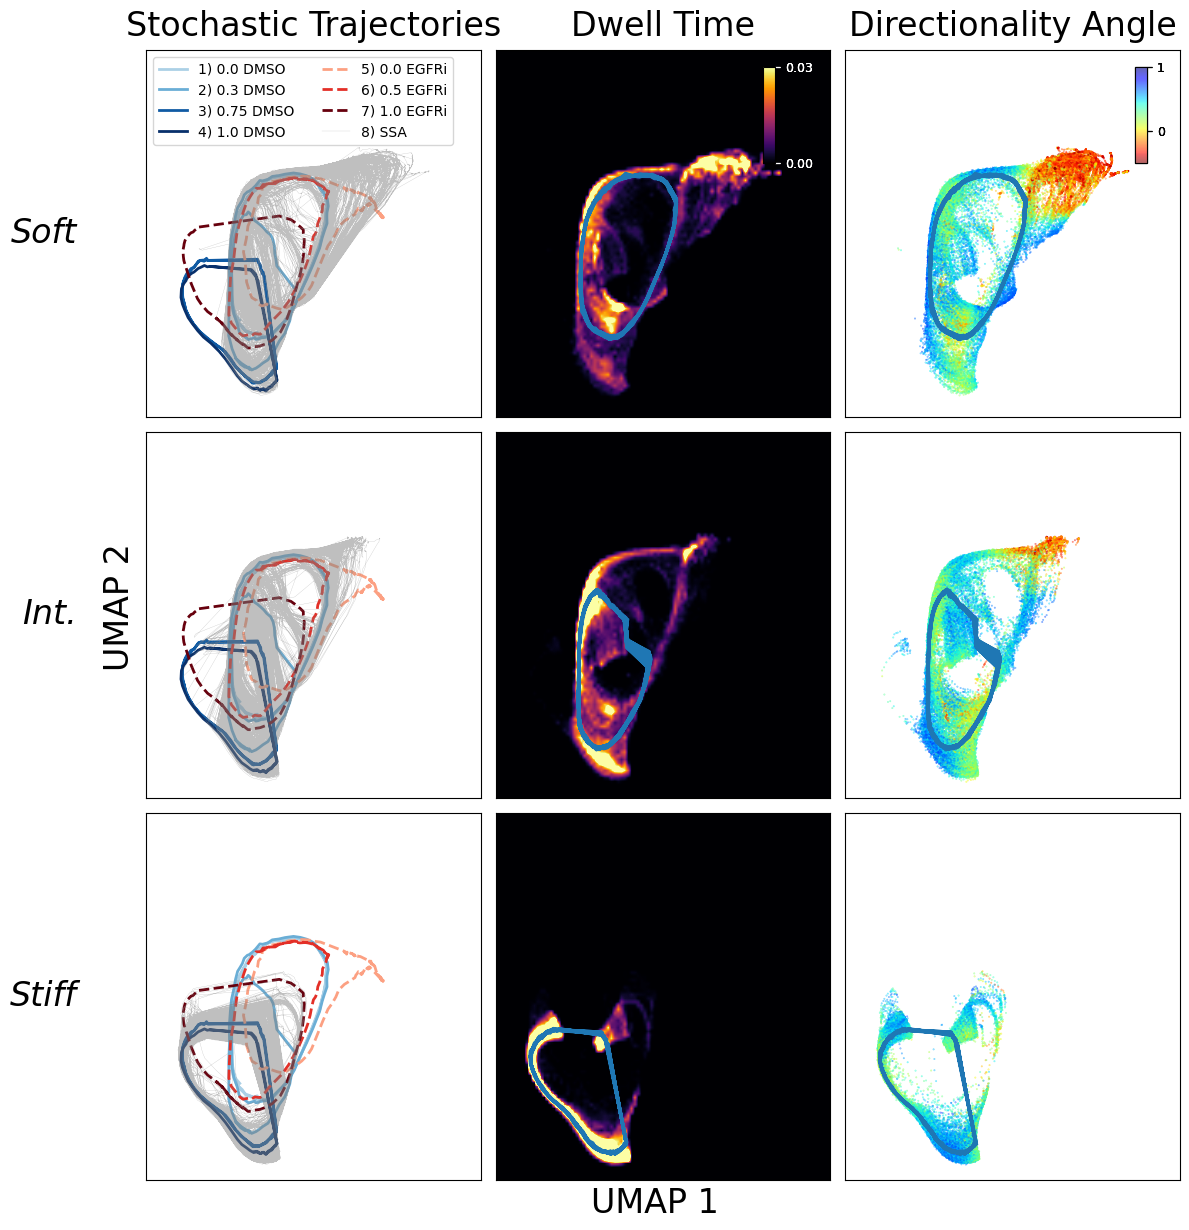

In [36]:
# Define figure size and grid
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
xmin = -10
xmax = 20
ymin = 0
ymax = 20

# Define row labels
row_labels = ['Soft', 'Int.', 'Stiff']

# Define column labels
col_labels = ['Stochastic Trajectories', 'Dwell Time', 'Directionality Angle']

# Column 1: Stochastic Trajectories
for cond_i, cond_x in enumerate([0, 2, 4]):
    lw = 2
    ax = axes[cond_i, 0]  # Select subplot
    
    for i, x in enumerate([0,1,3,4,5,7,9]):
        ax.plot(embed_array[x*l:x*l+plot_ode_len[x], 0],
                embed_array[x*l:x*l+plot_ode_len[x], 1],
                ls=line_type[x], lw=2, alpha=1, color=cond_colors[x], label=f'{i+1}) {conds[x]}')
    
    ax.plot(embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch, 0],
            embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch, 1],
            lw=0.2, alpha=0.5, color='gray', label=f'8) SSA')
    
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks([])
    ax.set_yticks([])
    if cond_i == 0:
        ax.legend(loc="upper left", ncol=2, fontsize=10)

# Column 2: Dwell Time
for cond_i, cond_x in enumerate([0, 2, 4]):
    val = ['000', '050', '099'][cond_i]
    dat_name = f'umap_win_dmso_{val}'
    dat = globals()[dat_name]
    ax = axes[cond_i, 1]
    
    x = np.array(dat[0])
    y = np.array(dat[1])
    H, xedges, yedges = np.histogram2d(x, y, bins=100, range=[[xmin, xmax], [ymin, ymax]], density=True)
    relative_H = np.divide(H, IMT_lens[cond_i+2])
    H2 = gaussian_filter(relative_H, [3, 3], mode='constant')
    
    im = ax.imshow(np.rot90(H), extent=[xmin, xmax, ymin, ymax], interpolation='bilinear', cmap='inferno', aspect='auto')
    im.set_clim(0, 0.03)

    tmp = all_embed_odes[cond_x*trk_len:(cond_x+1)*trk_len,:]
    ax.plot(tmp[200:,0], tmp[200:,1],
            lw=2, alpha=1)
    
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks([])
    ax.set_yticks([])
    
    cbar_ax = fig.add_axes([0.64, 0.86, 0.01, 0.08])
    cb = fig.colorbar(im, cax=cbar_ax, ticks=[0, 0.03])
    cb.ax.tick_params(labelsize=9)
    cb.ax.yaxis.set_tick_params(color='white')
    plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')

# Column 3: Directionality Angle
for cond_i, cond_x in enumerate([0, 2, 4]):
    cos_vals = get_cos_similarities(get_traj(all_prot, cond_x, trk_len_stoch), v_len, offset)
    ax = axes[cond_i, 2]
    dat = get_traj(embed_array_stoch, cond_x, trk_len_stoch-2)
    scatter1 = ax.scatter(dat[:, 0], dat[:, 1], s=0.15, alpha=0.6, vmin=-0.5, vmax=1, c=cos_vals, cmap='jet_r')
    
    tmp = all_embed_odes[cond_x*trk_len:(cond_x+1)*trk_len,:]
    ax.plot(tmp[200:,0], tmp[200:,1],
            lw=2, alpha=1)
    
    # if cond_x == 5:
    #     ax.plot(tmp[500:(500+plot_ode_len[cond_x]), 0], tmp[500:(500+plot_ode_len[cond_x]), 1],
    #         ls=line_type[cond_x], lw=2, alpha=1, color=cond_colors[cond_x], label=f'{conds[cond_x]}')
    #     ax.plot(low_cycle_embed_ode[:300, 0], low_cycle_embed_ode[:300, 1], lw=2, 
    #             alpha=1, color='blue', ls='--', label='Low Signal Attractor')
    # if cond_x == 7:
    #     tmp = get_traj(embed_array, 5, trk_len)
    #     ax.plot(tmp[500:(500+plot_ode_len[5]), 0], tmp[500:(500+plot_ode_len[5]), 1], 
    #             ls=line_type[5], lw=2, alpha=1, color=cond_colors[5], label='0.0 EGFRi')
    #     tmp = get_traj(embed_array, cond_x, trk_len)
    #     ax.plot(tmp[500:(500+plot_ode_len[cond_x]), 0], tmp[500:(500+plot_ode_len[cond_x]), 1],
    #         ls=line_type[cond_x], lw=2, alpha=1, color=cond_colors[cond_x], label=f'{conds[cond_x]}')
    #     tmp = get_traj(embed_array, 9, trk_len)
    #     ax.plot(tmp[500:(500+plot_ode_len[9]), 0], tmp[500:(500+plot_ode_len[9]), 1], 
    #             ls=line_type[9], lw=2, alpha=1, color=cond_colors[9], label='1.0 EGFRi')
    # if cond_x == 9:
    #     ax.plot(tmp[500:(500+plot_ode_len[cond_x]), 0], tmp[500:(500+plot_ode_len[cond_x]), 1],
    #         ls=line_type[cond_x], lw=2, alpha=1, color=cond_colors[cond_x], label=f'{conds[cond_x]}')
    #     tmp = get_traj(embed_array, 4, trk_len)
    #     ax.plot(tmp[500:(500+plot_ode_len[4]), 0], tmp[500:(500+plot_ode_len[4]), 1], 
    #             ls=line_type[4], lw=2, alpha=1, color=cond_colors[4], label='1.0 DMSO')

    # ax.legend(loc="upper left", fontsize=10)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks([])
    ax.set_yticks([])
    
    cbar_ax = fig.add_axes([0.95, 0.86, 0.01, 0.08])
    cb = fig.colorbar(scatter1, cax=cbar_ax, ticks=[0, 1], alpha=1)
    cb.ax.tick_params(labelsize=9)

# Add row labels
for ax, label in zip(axes[:, 0], row_labels):
    ax.set_ylabel(f'{label}', fontsize=24, labelpad=50, rotation=0, va='center', ha='right', style='italic')

# Add column labels
for ax, label in zip(axes[0], col_labels):
    ax.set_title(label, fontsize=24, pad=10)

# Global X and Y labels
fig.text(0.55, -0.015, 'UMAP 1', ha='center', fontsize=24)
fig.text(0.09, 0.49, 'UMAP 2', va='center', rotation='vertical', fontsize=24)

filepath = Path(SAVE_DIR,'fig5_DMSO.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', bbox_inches='tight', dpi=300)

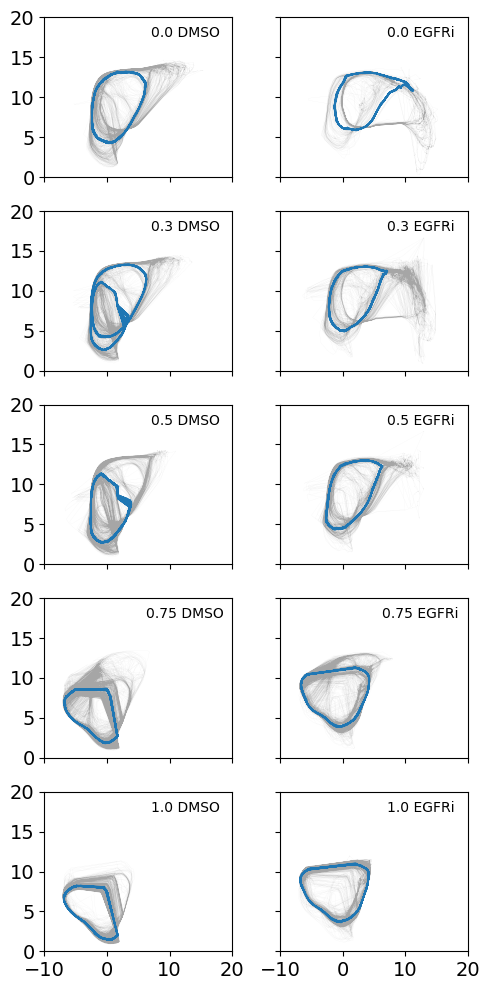

In [31]:
fig = plt.figure(figsize=(5,10))
p = 1
for n in [0,5,1,6,2,7,3,8,4,9]:
    plt.subplot(5,2,p)
    plt.plot(embed_array_stoch[n*trk_len_stoch:(n+1)*trk_len_stoch,0], 
             embed_array_stoch[n*trk_len_stoch:(n+1)*trk_len_stoch,1], lw=0.02, alpha=0.7, c='gray')
    plt.plot(embed_array[n*trk_len:(n+1)*trk_len,0], 
             embed_array[n*trk_len:(n+1)*trk_len,1], lw=1, alpha=1)

    plt.xlim(-10,20)
    plt.ylim(0, 20)

    ax = plt.gca()
    plt.text(0.75, 0.9, f'{conds[n]}', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
    if (p % 2) == 0:
        ax.yaxis.set_tick_params(labelleft=False)
    if p<9:
        ax.xaxis.set_tick_params(labelleft=False)
    p += 1